In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#here i am importing all libraries important to view and unddetstand the data.

In [2]:
#Load Data
df = pd.read_csv('car_price_dataset.csv')

#Checking Data Shape
print("Dataset Shape:", df.shape) 

#View Data
print("\nFirst 3 rows:")
display(df.head(3))
print("\nLast 3 rows:")
display(df.tail(3))


#observation: the data has 15411 listing of used cars with only 14 features across.

Dataset Shape: (15411, 14)

First 3 rows:


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.7,796,46.3,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.9,1197,82.0,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.0,1197,80.0,5,215000



Last 3 rows:


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
15408,19541,Skoda Rapid,Skoda,Rapid,6,67000,Dealer,Diesel,Manual,21.14,1498,103.52,5,425000
15409,19542,Mahindra XUV500,Mahindra,XUV500,5,3800000,Dealer,Diesel,Manual,16.00,2179,140.00,7,1225000
15410,19543,Honda City,Honda,City,2,13000,Dealer,Petrol,Automatic,18.00,1497,117.60,5,1200000


In [3]:
# Section 2
# Dataset Information & null values check
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB


In [ ]:
#observation: The dataset consists of :
               #integers (unnamed, vehicle_age, km_driven, engine, seats,selling price),
               #floats  (mileage, max_power) and 
               #objects (car_named, brand, model, seller_type, fuel_type, transmission_type)

In [5]:
#dropping useless columns, and saving memory: object to catergory

df_cleaned = df.drop(columns=['Unnamed: 0'])
categorical_cols = ['car_name', 'brand', 'model', 'seller_type', 
                    'fuel_type', 'transmission_type']
for col in categorical_cols:
    df_cleaned[col] = df_cleaned[col].astype('category')



,mean,std,min,50%,max
vehicle_age,6.040611,3.014693,0.0,6.00,29.00
km_driven,55643.602742,51768.220584,100.0,50000.00,3800000.00
mileage,19.697792,4.169227,4.0,19.67,33.54
engine,1486.172746,520.453492,793.0,1248.00,6592.00
max_power,100.607175,42.918455,38.4,88.50,626.00
seats,5.326860,0.806508,2.0,5.00,9.00
selling_price,774719.844837,894713.549241,40000.0,559000.00,39500000.00


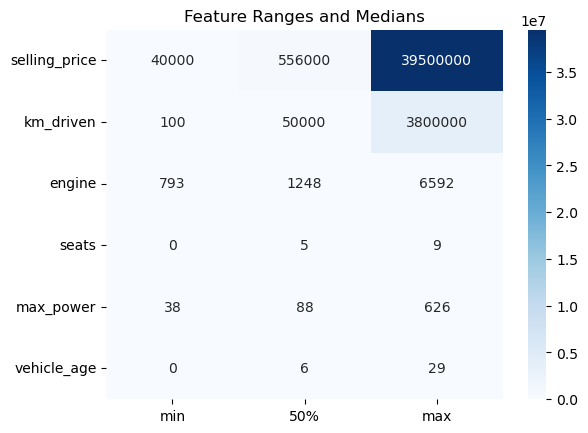

In [32]:
# Summary Statistics
display(df_cleaned.describe().T[['mean', 'std', 'min', '50%', 'max']])

#we are to display the descriptive stats of the features
stats = df[numeric_features].describe().T[['min','50%','max']]
sns.heatmap(stats, annot=True, cmap="Blues", fmt=".0f")
plt.title("Feature Ranges and Medians")
plt.show()

In [ ]:
#observation:
""" 
The average vehicle age is 6 years, with a standard deviation of 3 years, indicating that most 
vehicles are between 3 and 8 years old. The oldest used vehicle in the dataset is 29 years 
old, while the newest is 0 years old, representing brand-new vehicles or those that were sold 
with extremely low mileage of less than 100km. Vehicles have been driven an average of 
55616 km, although the higher standard deviation of 51619 km suggests considerable 
variation in usage. While 75% of vehicles have travelled 70000 km or less, one vehicle has 
travelled 3.8 million km, indicating a significant outlier. The average fuel mileage is 20 m/L, 
with values ranging from 4 km/L to 34 km/L. This suggests that most vehicles have moderate to good 
fuel efficiency, although some consume considerably more fuel than others 
(like the older cars with more km driven) reasons often stem from mechanical wear and tear.
The average engine capacity (cc) is 1486 while the average maximum power is 101. Most 
vehicles therefore fall within the small to medium-engine category. However, engine sizes 
range from 793 to 6592, and maximum power ranges from 38 to 626, showing that the dataset 
includes both economy vehicles up to high-performance vehicles. Most vehicles have 5 seats, as shown by 
both the mean and median values. The maximum number of seats is 9, indicating the presence of larger family or
commercial vehicles. However, the minimum value of 0 seats is unrealistic and likely represents a data entry 
error that should be investigated before further analysis. The average selling price is 774971, with a very high 
standard deviation of 894128, indicating substantial variation in vehicle prices. The median price is 556000, which
is considerably lower than the mean. This suggests that the selling price distribution is positively (right) skewed, 
where a small number of very expensive vehicles increase the average price. Prices (₹) range 
from 40000 to 39500000, confirming the presence of extreme high-value outliers."""

In [34]:
#checking missing values
print("\n These are number of missing values:")
display(df_cleaned.isnull().sum())  #zero missing values were found

# Handling Duplicates
duplicate_count = df_cleaned.duplicated().sum()
df_cleaned = df_cleaned.drop_duplicates().reset_index(drop=True)
print(f"Removed {duplicate_count} duplicate rows.") #which is 167 duplicated rows removed!

# Handling Corrupted/Invalid Data (Omit seats == 0)
# However, the minimum value of 0 seats is unrealistic and likely represents a data entry error that should 
# be investigated before further analysis.
rows_before = len(df_cleaned)
df_cleaned = df_cleaned.drop(df_cleaned[df_cleaned['seats'] == 0].index).reset_index(drop=True)
print(f"Omitted {rows_before - len(df_cleaned)} rows with invalid seats == 0.") 


 These are number of missing values:


car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

Removed 0 duplicate rows.
Omitted 0 rows with invalid seats == 0.


C:\Users\Joewy\AppData\Local\Temp\ipykernel_16532\2234217825.py:10: FutureWarning: Downcasting behavior in Series and DataFrame methods 'where', 'mask', and 'clip' is deprecated. In a future version this will not infer object dtypes or cast all-round floats to integers. Instead call result.infer_objects(copy=False) for object inference, or cast round floats explicitly. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data = df_cleaned[col].clip(upper=df_cleaned[col].quantile(0.99))


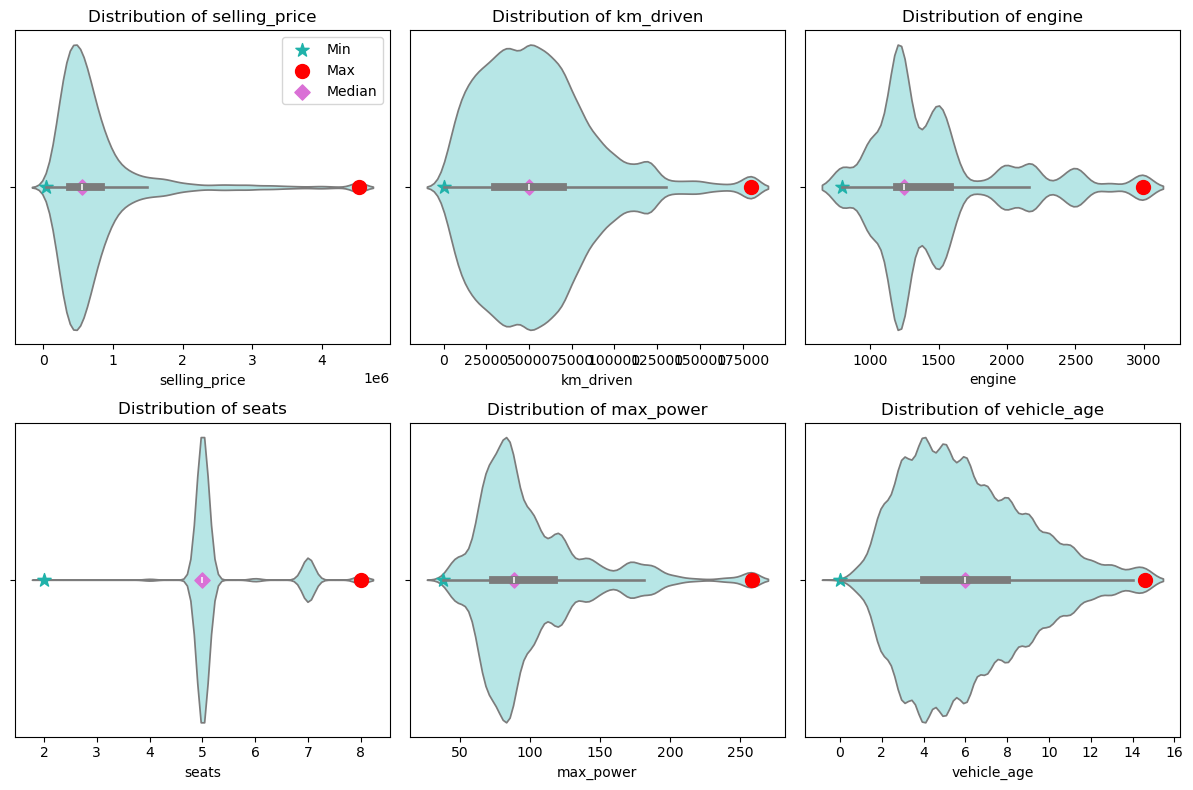

In [62]:
# checking for outliers in selected numerical features

numeric_features = ['selling_price', 'km_driven', 'engine', 'seats', 'max_power', 'vehicle_age']

plt.figure(figsize=(12, 8))
for i, col in enumerate(numeric_features, 1):
    plt.subplot(2, 3, i)
    
    # Clip extreme outliers at 99th percentile for clarity
    data = df_cleaned[col].clip(upper=df_cleaned[col].quantile(0.99))
    
    # Violin plot
    sns.violinplot(x=data, color='paleturquoise')
    
    # Add markers for min, max, and median
    plt.scatter(data.min(), 0, color='lightseagreen', marker='*', s=100, label='Min')
    plt.scatter(data.max(), 0, color='red', marker='o', s=100, label='Max')
    plt.scatter(data.median(), 0, color='orchid', marker='D', s=60, label='Median')
    
    # Title
    plt.title(f'Distribution of {col}')
    
    # Show legend only once
    if i == 1:
        plt.legend(loc='upper right')
        
plt.tight_layout()
plt.show()


In [63]:
# Outlier Removal (IQR Method)
#Retain realistic high-end values while filtering extreme recording errors
num_cols = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'selling_price']
Q1 = df_cleaned[num_cols].quantile(0.25)
Q3 = df_cleaned[num_cols].quantile(0.75)
IQR = Q3 - Q1

filter_mask = ~((df_cleaned['km_driven'] > (Q3['km_driven'] + 3 * IQR['km_driven'])) | 
                (df_cleaned['selling_price'] > (Q3['selling_price'] + 3 * IQR['selling_price'])))
df_filtered = df_cleaned[filter_mask].reset_index(drop=True)
print("Filtered Dataset Shape for Modeling:", df_filtered.shape)

Filtered Dataset Shape for Modeling: (14403, 13)


In [ ]:
#observation: we have noted that the two features km_driven and selling price contain large numbers,
#therefore performing a strict version of the IQR method was applied to remove the outliers.

In [64]:
##section 4

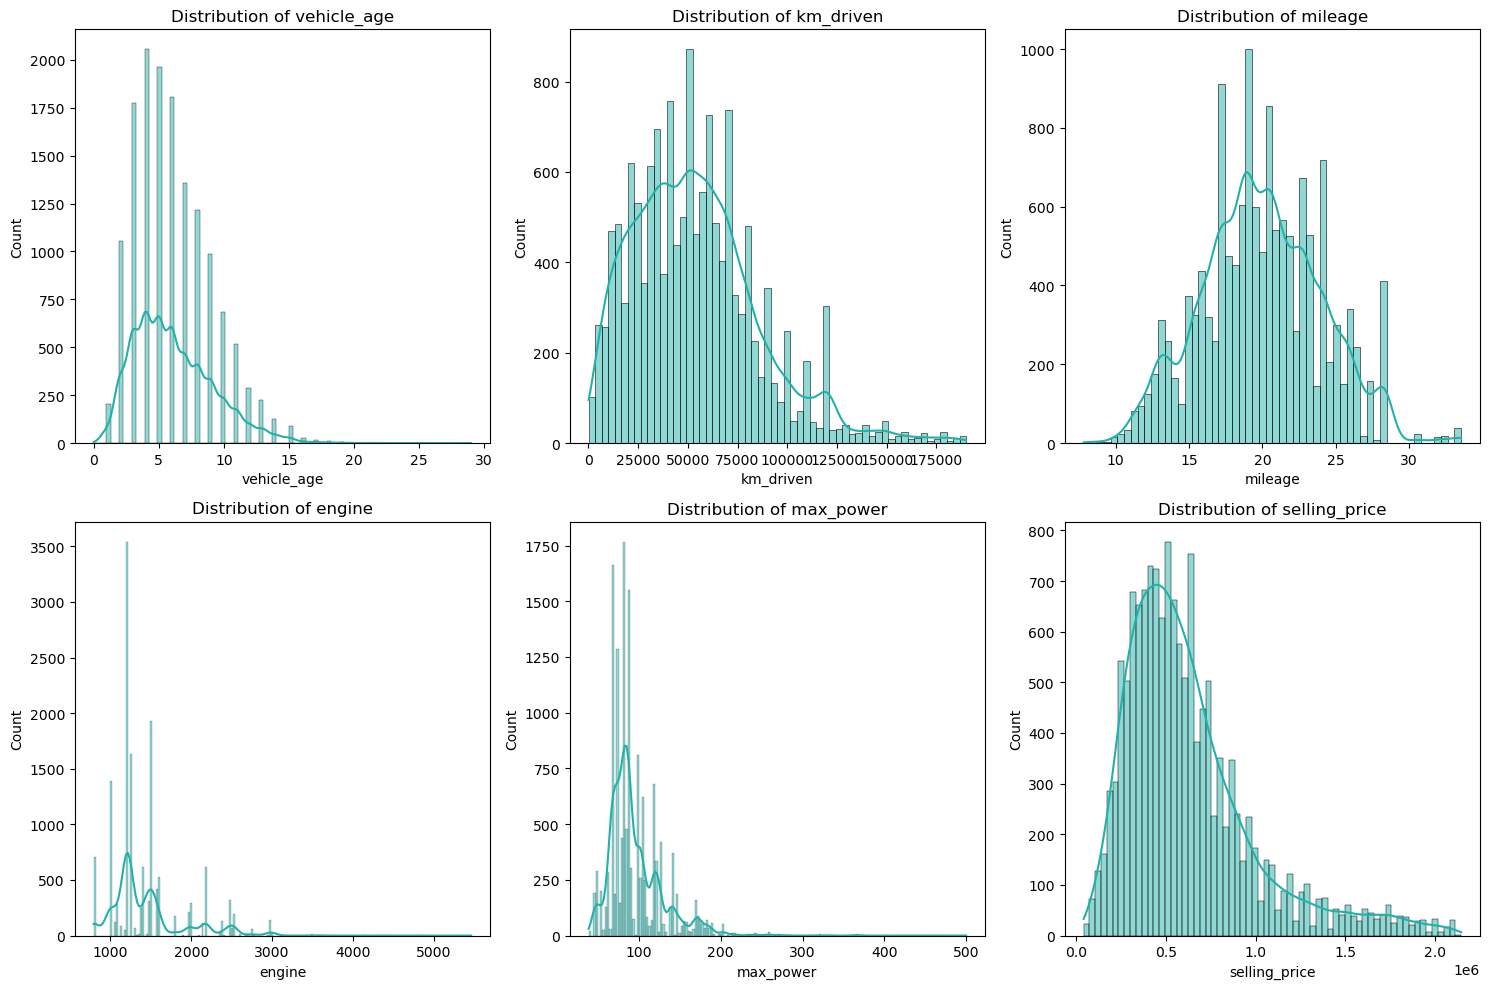

In [65]:
#Univariate Visual Analysis

# Plot Numerical Features
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols):
    plt.subplot(2, 3, i+1)
    sns.histplot(df_filtered[col], kde=True, color='lightseagreen')
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.savefig('num_univariate_dropped.png')
#plt.show()

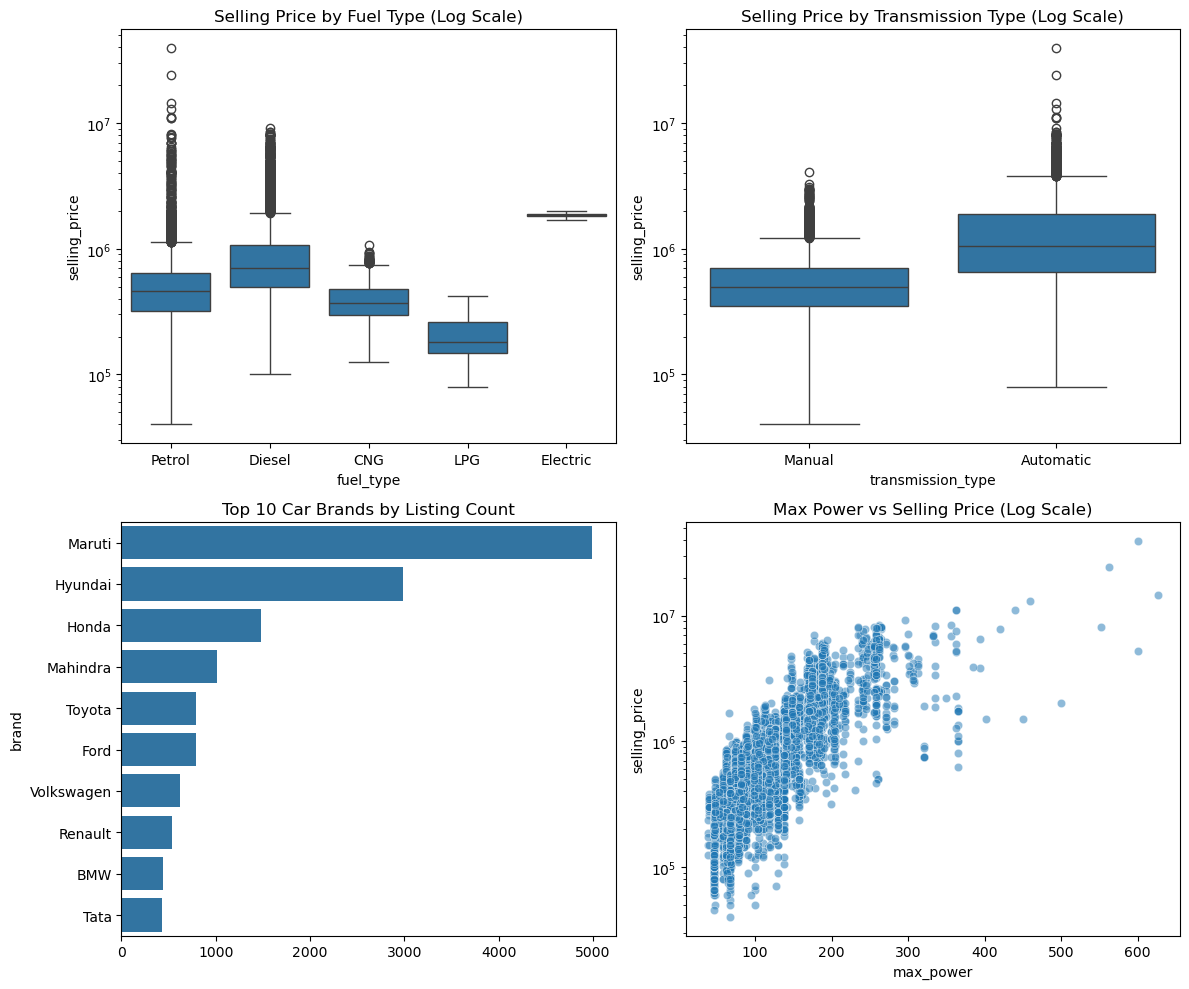

In [69]:
# concise summary of the Categorical features in the dataset in a visualised manner

plt.figure(figsize=(12, 10))

# Subplot 1: Price distribution by Fuel Type
plt.subplot(2, 2, 1)
sns.boxplot(data=df, x='fuel_type', y='selling_price')
plt.yscale('log')
plt.title('Selling Price by Fuel Type (Log Scale)')

# Subplot 2: Price distribution by Transmission Type
plt.subplot(2, 2, 2)
sns.boxplot(data=df, x='transmission_type', y='selling_price')
plt.yscale('log')
plt.title('Selling Price by Transmission Type (Log Scale)')

# Subplot 3: Top 10 Brands by Count
plt.subplot(2, 2, 3)
top_brands = df['brand'].value_counts().head(10)
sns.barplot(x=top_brands.values, y=top_brands.index)
plt.title('Top 10 Car Brands by Listing Count')

# Subplot 4: Mileage vs Selling Price
plt.subplot(2, 2, 4)
sns.scatterplot(data=df, x='max_power', y='selling_price', alpha=0.5)
plt.yscale('log')
plt.title('Max Power vs Selling Price (Log Scale)')

plt.tight_layout()
#plt.savefig('overview_plots.png')
plt.show()
plt.close()

In [ ]:
# Plot Categorical Distributions
""" The univariate analysis of the categorical variables revealed several notable patterns within 
the used car dataset. The brand variable was dominated by a few mass-market 
manufacturers, particularly Maruti and Hyundai, while many other brands appeared much less 
frequently, indicating a long-tail distribution. The seller_type analysis showed that most 
vehicles were listed by individual sellers rather than dealerships or trustmark dealers. 
Similarly, the fuel_type distribution indicated that petrol and diesel vehicles constituted the 
largest proportion of listings, whereas electric vehicles were relatively uncommon. 
Furthermore, the transmission_type analysis revealed that manual transmission vehicles 
significantly outnumbered automatic vehicles, reflecting the characteristics of the second-hand 
car market represented in the dataset."""

In [75]:
# Examine Skewness (before transformation)
print("Skewness before transformation:")
print(df_cleaned[num_cols].skew())

# Log Transformation for selling_price only
df_cleaned['selling_price_log'] = np.log1p(df_cleaned['selling_price'])

# Skewness after transformation
print("\nSkewness after transformation:")
print(df_cleaned[['selling_price', 'selling_price_log', 'km_driven']].skew())

# Note: km_driven is not log-transformed because strict 3*IQR filtering
# already reduced its skewness to a reasonable level.




Skewness before transformation:
vehicle_age       0.831484
km_driven        28.229363
mileage           0.109975
engine            1.669256
max_power         2.486525
selling_price    10.108912
dtype: float64

Skewness after transformation:
selling_price        10.108912
selling_price_log     0.565026
km_driven            28.229363
dtype: float64


In [79]:
# One-Hot Encoding for all categorical variables
# one-hot encoding was the best choice here because it creates clear binary indicators for each category without introducing random ranking.
df_ml = pd.get_dummies(df_filtered, columns=['brand', 'seller_type', 'fuel_type', 'transmission_type'], drop_first=True)

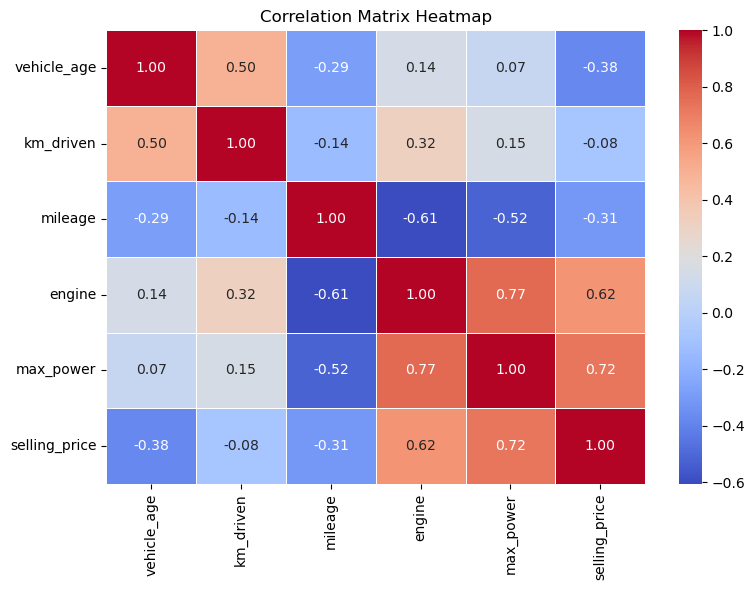

In [80]:
# correlation analysis and Heatmap Generation

plt.figure(figsize=(8, 6))
sns.heatmap(df_filtered[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.tight_layout()
plt.savefig('correlation_heatmap_dropped.png')

In [ ]:
''' observations: A heatmap was generated to visualize the correlation matrix, where values close to +1 indicate 
a strong positive relationship, values close to −1 indicate a strong negative relationship, and 
values close to 0 indicate little or no linear relationship 
selling_price has a strong positive correlation with max_power and engine size, more 
powerful, bigger-engine cars sell for more. selling_price has a moderate negative correlation 
with vehicle_age and km_driven this is because the older, higher-mileage cars sell for less, 
as expected for depreciating assets. selling_price has a negative correlation with mileage (km/l 
fuel efficiency) likely because smaller, more fuel-efficient, while economy cars tend to be 
cheaper, while powerful/premium cars are less fuel-efficient but more expensive. engine and 
max_power are strongly positively correlated with each other (larger engines produce more 
power) a sign of potential multicollinearity to watch for in any regression model. vehicle_age 
and km_driven are moderately positively correlated older cars have naturally accumulated 
more kilometers. seats show weak correlation with the other numeric features.'''

In [44]:
#section 5:Feature selection
# 5.1 Feature Selection using the absolute Correlation Threshold
full_corr = df_ml.drop(columns=['car_name', 'model', 'selling_price']).corr()['selling_price_log'].abs()

# Set threshold |r| >= 0.15
#this is statistically significant because n size is larger

threshold = 0.15
selected_features = full_corr[(full_corr >= threshold) & (full_corr.index != 'selling_price_log')].index.tolist()

print(f"Selected {len(selected_features)} features with |r| >= {threshold}:")
print(selected_features)


Selected 12 features with |r| >= 0.15:
['vehicle_age', 'mileage', 'engine', 'max_power', 'seats', 'brand_BMW', 'brand_Maruti', 'brand_Mercedes-Benz', 'brand_Toyota', 'fuel_type_Diesel', 'fuel_type_Petrol', 'transmission_type_Manual']


Top 12 Features Selected by SelectKBest:
                     Feature       F_Score        p_value
0                  max_power  10949.971681   0.000000e+00
1                     engine   6989.053071   0.000000e+00
2                vehicle_age   5662.792059   0.000000e+00
3           fuel_type_Diesel   2490.783738   0.000000e+00
4   transmission_type_Manual   2084.000612   0.000000e+00
5           fuel_type_Petrol   1995.575107   0.000000e+00
6               brand_Toyota   1254.224539  1.708108e-263
7                      seats   1225.953514  7.750308e-258
8               brand_Maruti   1114.793809  1.706996e-235
9                    mileage    722.449661  2.586925e-155
10                 brand_BMW    485.337469  8.175429e-106
11       brand_Mercedes-Benz    361.828320   1.065794e-79


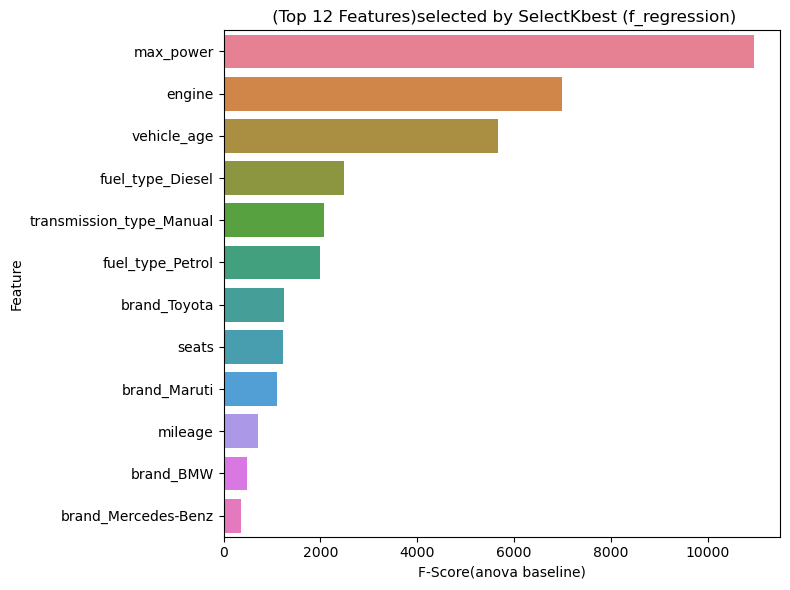

In [88]:
# 5.2 Feature Selection with SelectKBest


from sklearn.feature_selection import SelectKBest, f_regression
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Define candidate feature space and target
X_all = df_ml.drop(columns=['car_name', 'model', 'selling_price', 'selling_price_log'])
y = df_ml['selling_price_log']

# Perform ANOVA F-test based selection for top K=12 features
k = 12
selector = SelectKBest(score_func=f_regression, k=k)
selector.fit(X_all, y)

kbest_summary = pd.DataFrame({
    'Feature': X_all.columns,
    'F_Score': selector.scores_,
    'p_value': selector.pvalues_
}).sort_values(by='F_Score', ascending=False).reset_index(drop=True)

selected_kbest_features = kbest_summary['Feature'].head(k).tolist()
print(f"Top {k} Features Selected by SelectKBest:")
print(kbest_summary.head(k))

#here i will visualise the top 12 features by selectkbest
plt.figure(figsize=(8, 6))
sns.barplot(
    x=kbest_summary['F_Score'].head(k),
    y=kbest_summary['Feature'].head(k),
    hue=kbest_summary['Feature'].head(k),  
    dodge=False,
    palette="husl"  
)
plt.title(f" (Top {k} Features)selected by SelectKbest (f_regression)")
plt.xlabel("F-Score(anova baseline)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
#plt.savefig('Top12.png')

In [ ]:
'''OBSERVATIONS:Max_power, engine, and vehicle_age dominate the feature importance, showing the strongest statistical relationship
   with the target variable (selling_price_log). This makes sense because these directly reflect car performance and age,
   which are key drivers of resale value. Fuel type (Diesel, Petrol) and transmission type (Manual) also rank highly, 
   indicating that drivetrain and fuel choice significantly influence pricing. Brand effects are visible: Toyota and Maruti 
   appear in the middle range, while luxury brands like BMW and Mercedes-Benz show weaker but still notable influence.Seats and mileage 
   contribute moderately, suggesting they matter but not as strongly as powertrain or age. The spread of F-scores shows a steep drop 
   after the top 3 features, meaning most predictive power is concentrated in a few variables.

In [ ]:
#section 6

In [99]:
#IMPORTING IMPORTANT LIBRARIES FOR MODEL SELECTION AND TRAINING 

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


In [100]:
# Feature engineering using (K=12) Features from above section by ANOVA
X = df_ml[selected_kbest_features]
y = df_ml['selling_price_log']

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standard Scaling for Regularized Linear Models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [101]:
# Baseline Linear Regression (no tuning performed because LR has no meaningful hyperparameters)
lr_best = LinearRegression()
lr_best.fit(X_train_scaled, y_train)   # Fit baseline model on scaled training data

# Hyperparameter Tuning for Random Forest

rf_param_grid = {
    'n_estimators': [100, 200, 300],   # number of trees in the forest
    'max_depth': [10, 15, 20],         # maximum depth of each tree
    'min_samples_split': [2, 5],       # minimum samples required to split a node
    'min_samples_leaf': [1, 2]         # minimum samples required at a leaf node
}

# We here perform a 5-fold cross-validation gridcv search using R² as scoring metric
rf_grid = GridSearchCV(RandomForestRegressor(random_state=42),
                       param_grid=rf_param_grid,
                       cv=5,
                       scoring='r2',
                       n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("Best RF Params:", rf_grid.best_params_)
rf_best = rf_grid.best_estimator_      

# Hyperparameter Tuning for Gradient Boosting
# Define parameter grid for boosting iterations, learning rate, depth, and subsampling
gb_param_grid = {
    'n_estimators': [100, 200],        # this is the number of boosting stages
    'learning_rate': [0.05, 0.1, 0.2], # shrinkage rate applied to each tree
    'max_depth': [3, 5, 7],            # maximum depth of individual trees
    'subsample': [0.8, 1.0]            # fraction of samples used for fitting each base learner
}

# here we are to perfrom grid search with 5-fold cross-validation using R² as scoring metric
gb_grid = GridSearchCV(GradientBoostingRegressor(random_state=42),
                       param_grid=gb_param_grid,
                       cv=5,
                       scoring='r2',
                       n_jobs=-1)
gb_grid.fit(X_train, y_train)
print("Best GB Params:", gb_grid.best_params_)
gb_best = gb_grid.best_estimator_      

Best RF Params: {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best GB Params: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 200, 'subsample': 1.0}


In [ ]:
# comment: We did not perform hyperparameter tuning for Linear Regression because the model has no meaningful hyperparameters 
#to optimize, its coefficients. Unlike Random Forest or Gradient Boosting, which rely on parameters such as tree depth,
#number of estimators, plain Linear Regression is essentially fixed. 

In [ ]:
##SECTION 7

In [103]:
# Model Evaluation and Comparison


results = [] # to store results for each model

# i will create a dictionary of trained models
models = {
    "Linear Regression (Baseline)": lr_best,
    "Random Forest (Tuned)": rf_best,
    "Gradient Boosting (Tuned)": gb_best
}

# Loop through models and evaluate performance
for name, model in models.items():
    if "Linear Regression" in name:
        y_pred = model.predict(X_test_scaled)
    else:
        y_pred = model.predict(X_test)
    

    results.append({
        "Model": name,
        "R²": r2_score(y_test, y_pred),                       # Coefficient of determination
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),  # Root Mean Squared Error
        "MAE": mean_absolute_error(y_test, y_pred)            # Mean Absolute Error
    })

# Convert results to DataFrame for neat display
results_df = pd.DataFrame(results)

print("\n============== Model Performance Comparison ===============")
display(results_df)



============== Model Performance Comparison ===============


,Model,R²,RMSE,MAE
0,Linear Regression (Baseline),0.830544,0.235344,0.179160
1,Random Forest (Tuned),0.899390,0.181341,0.131617
2,Gradient Boosting (Tuned),0.905098,0.176122,0.127944


In [ ]:
#Linear Regression performed the worst due to the non-linear nature of car pricing.
#Random Forest significantly outperformed Linear Regression by capturing non-linear relationships.
#Gradient Boosting (Tuned) was the best-performing model. The R² score of ~0.89 indicates that the model explains 89% of the variance in car prices.

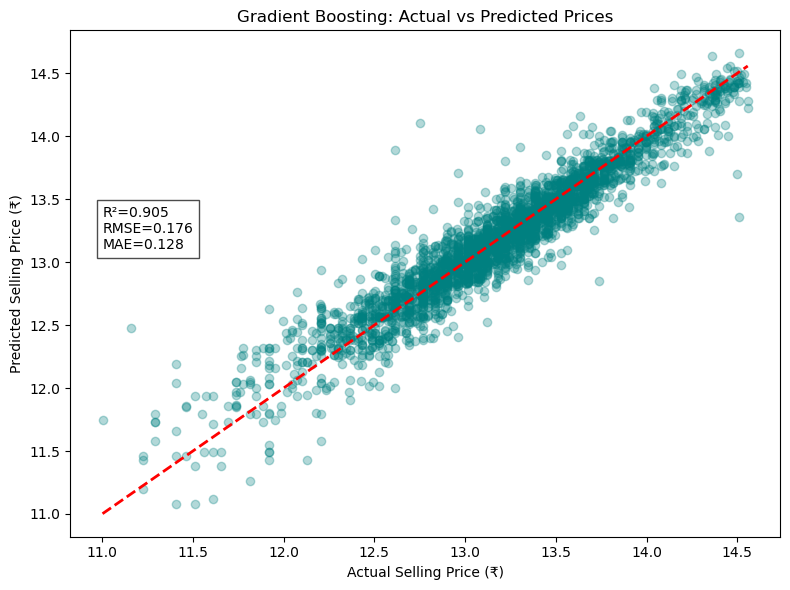

In [109]:
#plotting the best model visually
# Plot: Predicted vs Actual Prices
# Extract metrics for Gradient Boosting from results_df

metrics_gb = results_df[results_df['Model'] == "Gradient Boosting (Tuned)"].iloc[0]

# Plot: Predicted vs Actual Prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, gb_best.predict(X_test), alpha=0.3, color='teal')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--', lw=2)

# Annotate with metrics from results_df
plt.text(y_test.min(), y_test.max()*0.9,
         f"R²={metrics_gb['R²']:.3f}\nRMSE={metrics_gb['RMSE']:.3f}\nMAE={metrics_gb['MAE']:.3f}",
         fontsize=10, bbox=dict(facecolor='white', alpha=0.7))

plt.xlabel('Actual Selling Price (₹)')
plt.ylabel('Predicted Selling Price (₹)')
plt.title('Gradient Boosting: Actual vs Predicted Prices')
plt.tight_layout()
#plt.show()
plt.savefig('gradBoost.png')



In [ ]:
### section 8

In [108]:
import pickle

# Save tuned Gradient Boosting Regressor model and selected features
model_artifacts = {
    'model': gb_best,
    'selected_features': selected_kbest_features   # use the correct variable name
}

with open('car_price_gb_model.pkl', 'wb') as f:
    pickle.dump(model_artifacts, f)

print("Tuned Gradient Boosting model successfully saved to 'car_price_gb_model.pkl'.")


Tuned Gradient Boosting model successfully saved to 'car_price_gb_model.pkl'.
